### *Mauricio Rios Cantillo - Jose Bonett Pertuz - Jorge Jaraba Potes - Jordan Caro Batista*

##### **CLASIFICACION DE VOCALES QUE ESTAN EN IMAGENES POR MEDIO DE MACHINE LEARNING**
---

# Descripción del problema

En el presente trabajo se busca construir un modelo de aprendizaje automático capaz de identificar qué vocal (A, E, I, O o U) aparece en una imagen. Se trata de un problema de **clasificación supervisada multiclase**: cada imagen pertenece a una sola de las cinco clases.

El conjunto de datos original de Kaggle(https://www.kaggle.com/datasets/straighttoheaven/handwriting-letter-and-number-dataset) contiene 35 carpetas con imágenes de letras y números. Para este trabajo se extrajeron manualmente únicamente las carpetas de las vocales, que son las clases que se requiere identificar. La vocal **O** corresponde a la carpeta `0`.

Objetivos específicos:

*   Explorar y describir el conjunto de imágenes de vocales.
*   Aplicar técnicas de procesamiento a las imágenes (conversión a escala de grises, entre otras).
*   Implementar y evaluar modelos de aprendizaje de máquina para clasificar las vocales.

#### Objetivo de esta etapa

Antes de entrenar cualquier modelo, en esta etapa se busca comprender cómo está organizado el conjunto de datos y verificar su calidad: la cantidad de imágenes por vocal, sus dimensiones, número de canales y formato, la distribución de ejemplos entre clases y las variaciones visuales entre imágenes. Como parte del preprocesamiento, las imágenes se convertirán a escala de grises para garantizar que todas tengan un único canal.

### Descripción de variables

El conjunto de datos está formado por imágenes organizadas en carpetas, una por cada vocal:

*   La variable predictora **X** corresponde a la imagen de la vocal. Cada imagen se representa como una matriz de píxeles con valores de intensidad entre 0 (negro) y 255 (blanco).
*   La variable objetivo **Y** corresponde a la vocal que aparece en la imagen (A, E, I, O, U). Se obtiene del nombre de la carpeta que contiene cada imagen.

#### Importación de librerías

Se importan las librerías necesarias para recorrer las carpetas del dataset, leer y procesar las imágenes, organizar los datos en tablas y construir las visualizaciones.

In [2]:
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import skimage as ski
import os
import pandas as pd
import numpy as np
import statistics
import skimage.io as io
import skimage.exposure as ske
import warnings


from pathlib import Path
from skimage.color import rgb2gray
from skimage.transform import resize



from sklearn.preprocessing import MinMaxScaler


from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split 
from sklearn.metrics import accuracy_score
from sklearn import metrics


from sklearn.metrics import classification_report
from sklearn import tree


from sklearn.model_selection import GridSearchCV
from sklearn.neural_network import MLPClassifier
from sklearn.exceptions import ConvergenceWarning


### Cargando el conjunto de datos

El conjunto de datos está organizado en carpetas, una por cada vocal. A continuación se listan las carpetas que contiene.

In [3]:
RUTA = "Only Vowels"
carpetas = sorted(os.listdir(RUTA))
print("Carpetas encontradas:", carpetas)
print("Número de carpetas:", len(carpetas))

Carpetas encontradas: ['0', 'A', 'E', 'I', 'U']
Número de carpetas: 5


El conjunto de datos contiene 5 carpetas: `0`, `A`, `E`, `I` y `U`. Cada carpeta corresponde a una clase (vocal), y el nombre de la carpeta es la etiqueta de las imágenes que contiene. La carpeta `0` contiene las imágenes de la vocal **O**.

### Archivos del conjunto de datos

Se revisan los nombres de los archivos de una carpeta y las extensiones presentes en todo el conjunto de datos.

In [4]:
archivos_A = sorted(os.listdir(os.path.join(RUTA, "A")))
print("Primeros 5 archivos de la carpeta A  :")
for archivo in archivos_A[:5]:
    print("  ", archivo)

extensiones = {os.path.splitext(f)[1].lower()
               for c in carpetas
               for f in os.listdir(os.path.join(RUTA, c))}
print("Extensiones encontradas en todo el dataset:", extensiones)

Primeros 5 archivos de la carpeta A  :
   aug100_19.jpg
   aug100_9.jpg
   aug101_0.jpg
   aug102_1.jpg
   aug103_2.jpg
Extensiones encontradas en todo el dataset: {'.jpg'}


Todas las imágenes están en formato **JPEG** (`.jpg`). Los archivos siguen el patrón `augNNNN_N.jpg`

### Número de casos

Se cuenta la cantidad de imágenes de cada vocal y el total del conjunto de datos.

In [5]:
nombre_vocal = {"0": "O", "A": "A", "E": "E", "I": "I", "U": "U"}

conteos = []
for carpeta in carpetas:
    cantidad = len(os.listdir(os.path.join(RUTA, carpeta)))
    conteos.append({"Vocal": nombre_vocal[carpeta], "Carpeta": carpeta, "Cantidad": cantidad})

df_conteos = pd.DataFrame(conteos).sort_values("Vocal").reset_index(drop=True)
df_conteos["Porcentaje (%)"] = (df_conteos["Cantidad"] / df_conteos["Cantidad"].sum() * 100).round(2)

print(df_conteos.to_string(index=False))
print("\nTotal de imágenes (casos):", df_conteos["Cantidad"].sum())

Vocal Carpeta  Cantidad  Porcentaje (%)
    A       A      1010           19.92
    E       E      1010           19.92
    I       I      1010           19.92
    O       0      1030           20.32
    U       U      1010           19.92

Total de imágenes (casos): 5070


El conjunto de datos tiene **5070 casos** (imágenes). Las vocales A, E, I y U tienen 1010 imágenes cada una (19,92 %), y la vocal O tiene 1030 (20,32 %).

### Distribución de las clases

En la siguiente gráfica de barras se observa la cantidad de imágenes por vocal.

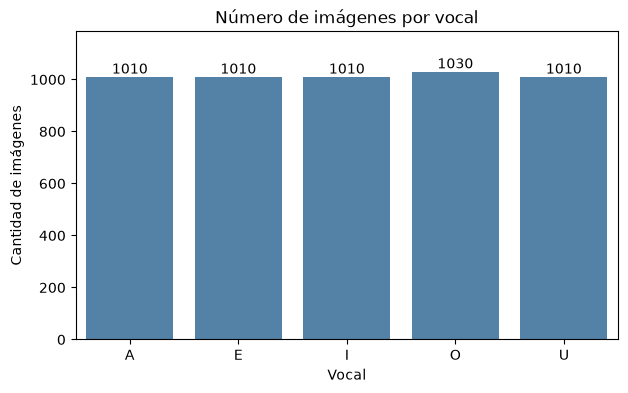

In [6]:
plt.figure(figsize=(7, 4))
ax = sns.barplot(data=df_conteos, x="Vocal", y="Cantidad", color="steelblue")
ax.bar_label(ax.containers[0])
plt.title("Número de imágenes por vocal")
plt.xlabel("Vocal")
plt.ylabel("Cantidad de imágenes")
plt.ylim(0, df_conteos["Cantidad"].max() * 1.15)
plt.show()

Las clases están **balanceadas**: la diferencia entre la clase más grande (O, 1030) y las demás (1010) es de solo 20 imágenes, menos del 2 %. Esto evita que un modelo se incline hacia una clase en particular.

### Representación de las imágenes

Se muestra un ejemplo de cada vocal y se revisa cómo se representa una imagen internamente, es decir, la variable predictora X.

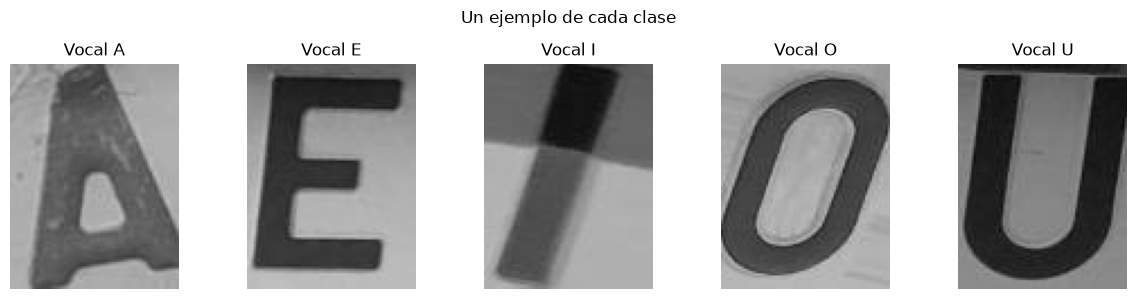

In [7]:
fig, axes = plt.subplots(1, len(carpetas), figsize=(12, 3))
for ax, carpeta in zip(axes, sorted(carpetas, key=lambda c: nombre_vocal[c])):
    primer_archivo = sorted(os.listdir(os.path.join(RUTA, carpeta)))[0]
    img = ski.io.imread(os.path.join(RUTA, carpeta, primer_archivo))
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Vocal {nombre_vocal[carpeta]}")
    ax.axis("off")
plt.suptitle("Un ejemplo de cada clase")
plt.tight_layout()
plt.show()

In [8]:
ruta_ejemplo = os.path.join(RUTA, "A", archivos_A[0])
img = ski.io.imread(ruta_ejemplo)

print("Archivo:", ruta_ejemplo)
print("Tipo de objeto:", type(img))
print("Forma (alto, ancho):", img.shape)
print("Número de dimensiones:", img.ndim)
print("Tipo de dato:", img.dtype)
print("Valor mínimo:", img.min(), "| Valor máximo:", img.max())
print("Número total de píxeles (variables de entrada):", img.size)
print("\nFragmento de la matriz (filas 45 a 49, columnas 30 a 37):")
print(img[45:50, 30:38])

Archivo: Only Vowels\A\aug100_19.jpg
Tipo de objeto: <class 'numpy.ndarray'>
Forma (alto, ancho): (100, 75)
Número de dimensiones: 2
Tipo de dato: uint8
Valor mínimo: 59 | Valor máximo: 194
Número total de píxeles (variables de entrada): 7500

Fragmento de la matriz (filas 45 a 49, columnas 30 a 37):
[[ 83  83  82  81  79  77  76  77]
 [ 82  80  79  77  74  72  71  73]
 [ 82  79  77  75  71  68  68  71]
 [ 79  80  74  70  69  87 114 122]
 [ 81  79  65  76  91 119 149 158]]


Cada imagen se carga como un arreglo de NumPy de forma **(100, 75)**: 100 píxeles de alto por 75 de ancho. Tiene **2 dimensiones**, lo que indica que está en escala de grises (un solo canal). Los valores son enteros de 8 bits (`uint8`) en el rango 0–255, donde 0 es negro y 255 blanco. En total, cada imagen aporta **7500 píxeles**, que son los valores numéricos con los que el modelo trabajará como variable predictora X.

# Inspección y exploración del Dataset

En esta sección se explora el conjunto de datos mediante herramientas gráficas (cuadrículas de imágenes, histogramas, diagramas de caja y mapas de calor), resúmenes estadísticos y matrices de correlación.

Como los datos son imágenes. Además de inspeccionarlas visualmente, se calculan **características estadísticas de cada imagen** (brillo, contraste, proporción de la letra, nitidez, etc.) para poder resumirlas y analizar su distribución y sus correlaciones.

### Carga de las imágenes y conversión a escala de grises

Se cargan todas las imágenes en memoria. Para garantizar que todas tengan un solo canal, se define la función `cargar_en_gris()`: si una imagen viene a color, la convierte a escala de grises; si ya está en gris, la deja igual. Las imágenes se guardan en el arreglo **X** y sus etiquetas en **y**.

In [9]:
def cargar_en_gris(ruta):
    img = ski.io.imread(ruta)
    if img.ndim == 3:                    # imagen con varios canales (color)
        if img.shape[2] == 4:            # se descarta el canal de transparencia
            img = img[:, :, :3]
        img = ski.util.img_as_ubyte(rgb2gray(img))  # a gris, en rango 0-255
    return img

imagenes, etiquetas = [], []
for carpeta in carpetas:
    for archivo in sorted(os.listdir(os.path.join(RUTA, carpeta))):
        imagenes.append(cargar_en_gris(os.path.join(RUTA, carpeta, archivo)))
        etiquetas.append(nombre_vocal[carpeta])

X = np.array(imagenes)
y = np.array(etiquetas)
vocales = sorted(np.unique(y))

print("Forma de X:", X.shape)
print("Forma de y:", y.shape)

Forma de X: (5070, 100, 75)
Forma de y: (5070,)


Se cargaron las 5070 imágenes. **X** tiene forma (5070, 100, 75): 5070 imágenes de 100 × 75 píxeles. **y** contiene las 5070 etiquetas correspondientes.

### Inspección visual de una muestra aleatoria

Se seleccionan 8 imágenes al azar de cada vocal y se muestran en una cuadrícula, una fila por vocal.

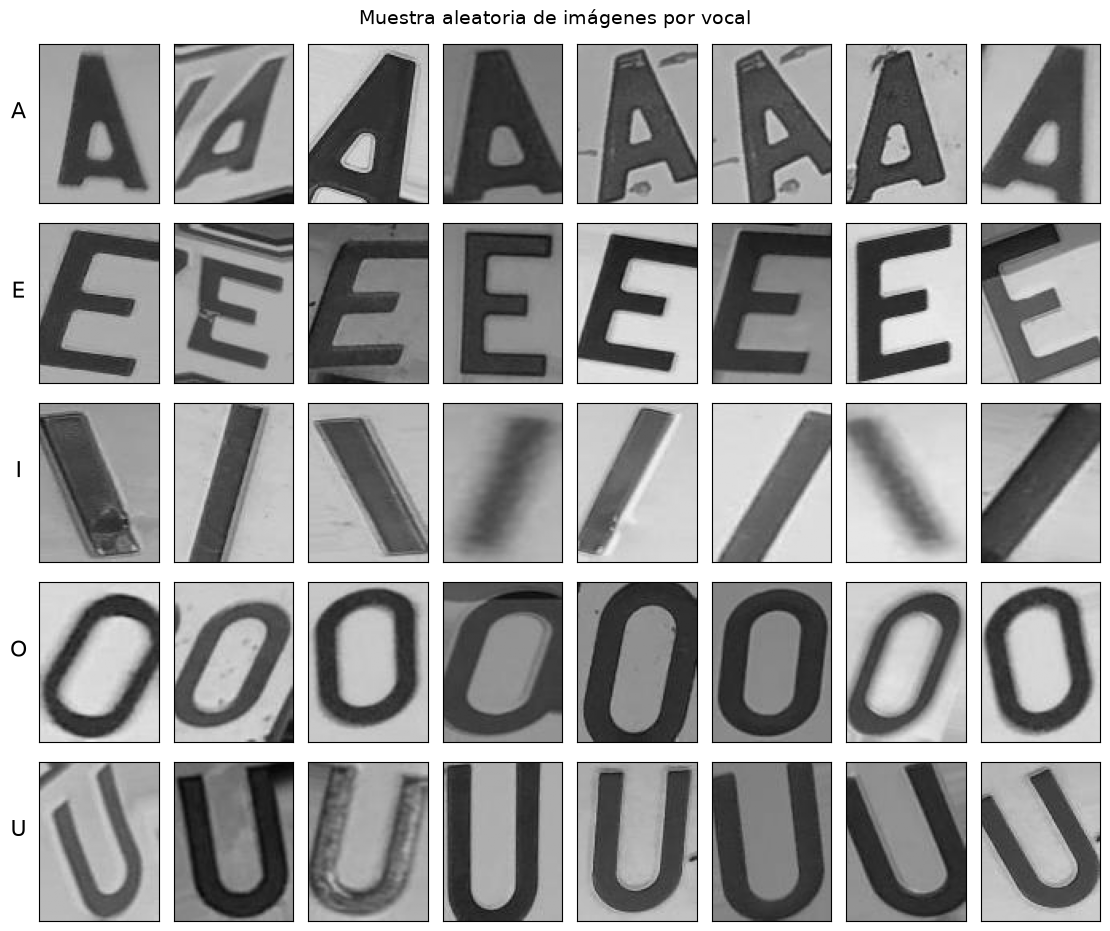

In [10]:
rng = np.random.default_rng(42)  # semilla para que la muestra sea reproducible
N = 8

fig, axes = plt.subplots(len(vocales), N, figsize=(N * 1.4, len(vocales) * 1.9))
for i, vocal in enumerate(vocales):
    indices = rng.choice(np.where(y == vocal)[0], size=N, replace=False)
    for j, idx in enumerate(indices):
        ax = axes[i, j]
        ax.imshow(X[idx], cmap="gray", vmin=0, vmax=255)
        ax.set_xticks([])
        ax.set_yticks([])
        if j == 0:
            ax.set_ylabel(vocal, fontsize=16, rotation=0, labelpad=15)
fig.suptitle("Muestra aleatoria de imágenes por vocal", fontsize=14)
plt.tight_layout()
plt.show()

Al observar la muestra se identifican las siguientes variaciones:

*   **Tipo de letra:** aunque el dataset en Kaggle se llama *Handwriting*, las imágenes no parecen escritas a mano, sino fotografías de letras físicas (como las de placas o letreros) con una misma tipografía.
*   **Rotación:** muchas letras aparecen giradas o inclinadas, sobre todo la I y la O.
*   **Escala y recorte:** en algunas imágenes la letra llena el cuadro y queda cortada en los bordes; en otras se ve completa.
*   **Fondo e iluminación:** el fondo va de gris claro a gris oscuro y el contraste entre letra y fondo cambia de una imagen a otra.
*   **Ruido:** algunas imágenes presentan desenfoque, manchas o rayones.
*   La **I** es la vocal más difícil de reconocer a simple vista, porque es solo una barra y con rotación o recorte pierde su forma.

# Imagen promedio de cada vocal

Se calcula el promedio, píxel a píxel, de todas las imágenes de cada vocal. Esto muestra la forma "típica" de cada clase.

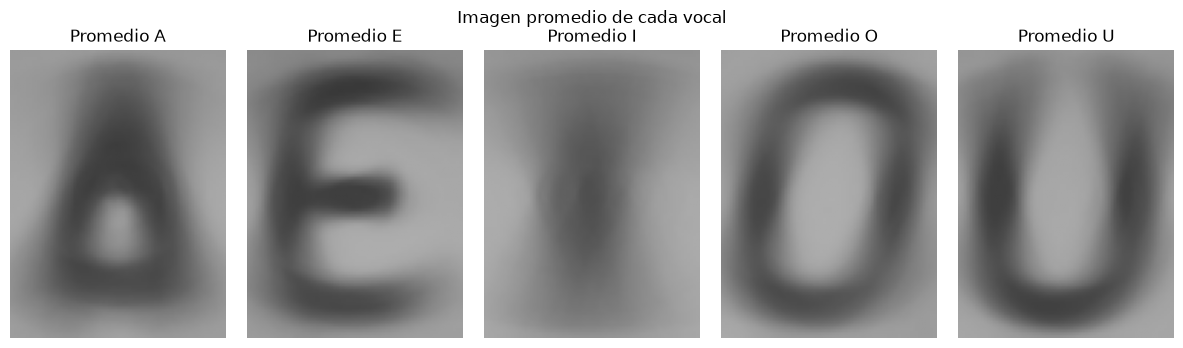

In [11]:
promedios = {}
fig, axes = plt.subplots(1, len(vocales), figsize=(12, 3.5))
for ax, vocal in zip(axes, vocales):
    promedios[vocal] = X[y == vocal].mean(axis=0)
    ax.imshow(promedios[vocal], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Promedio {vocal}")
    ax.axis("off")
fig.suptitle("Imagen promedio de cada vocal")
plt.tight_layout()
plt.show()

A pesar de las rotaciones y variaciones, la imagen promedio de cada vocal conserva una forma reconocible: se distinguen claramente la A, la E, la O y la U. Esto indica que la posición de los píxeles oscuros contiene información útil para clasificar. La **I** es la excepción: su promedio es una mancha difusa, porque la barra aparece en distintas posiciones e inclinaciones. Esto confirma que será la clase más difícil.

También se observa que la O y la U tienen promedios parecidos (ambas tienen trazos verticales a los lados y una curva en la parte inferior), lo que anticipa posibles confusiones entre ellas.

### Distribución de intensidades de los píxeles

Se construye un histograma con los valores de todos los píxeles de cada vocal (de 0 = negro a 255 = blanco).

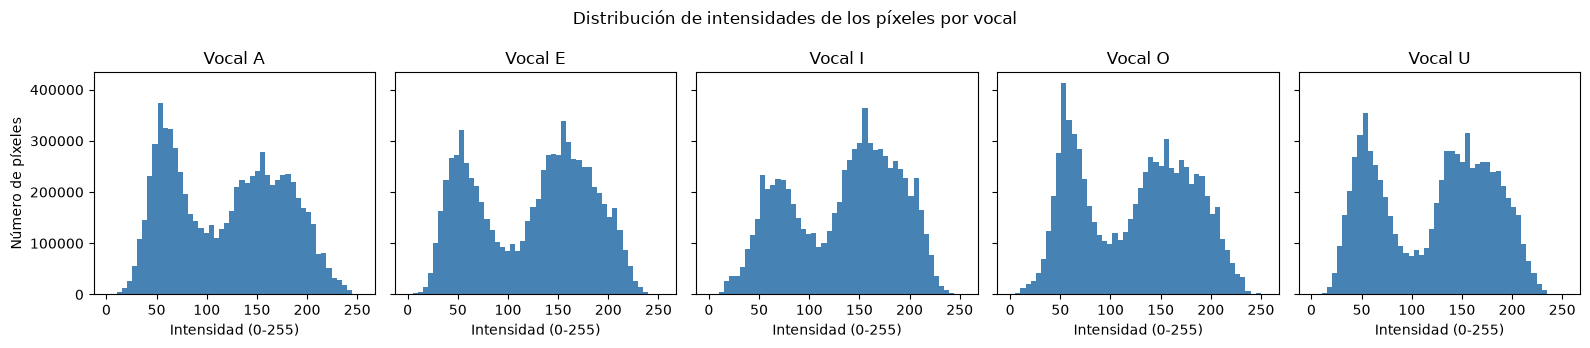

In [12]:
fig, axes = plt.subplots(1, len(vocales), figsize=(16, 3.5), sharey=True)
for ax, vocal in zip(axes, vocales):
    ax.hist(X[y == vocal].ravel(), bins=50, range=(0, 255), color="steelblue")
    ax.set_title(f"Vocal {vocal}")
    ax.set_xlabel("Intensidad (0-255)")
axes[0].set_ylabel("Número de píxeles")
fig.suptitle("Distribución de intensidades de los píxeles por vocal")
plt.tight_layout()
plt.show()

Todos los histogramas tienen dos picos:

*   Un pico en valores bajos (alrededor de 50–60), que corresponde a los píxeles oscuros de la **letra**.
*   Un pico en valores medios-altos (alrededor de 150–170), que corresponde al **fondo**, más claro.

Esta separación indica que la letra y el fondo se pueden distinguir bien por su intensidad. En la **I**, el pico oscuro es más bajo que en las demás vocales porque la letra ocupa una menor parte de la imagen. En la **A** y la **O** ese pico es el más alto, porque su trazo cubre más área.

### Extracción de características estadísticas por imagen

Para resumir cada imagen con pocos valores, se calculan las siguientes características:

| Característica | Descripción |
|---|---|
| `brillo` | Intensidad promedio de la imagen. |
| `contraste` | Desviación estándar de las intensidades . |
| `pixel_mas_oscuro` | Intensidad más oscura de la imagen. |
| `pixel_mas_claro` | Intensidad más clara de la imagen. |
| `area_letra` | Fracción de píxeles que pertenecen a la letra.
| `definicion_bordes` | Mide qué tan definidos son los bordes. Valores bajos indican una imagen borrosa. |

In [19]:
def caracteristicas(img):
    umbral = ski.filters.threshold_otsu(img)
    return {
        "brillo": img.mean(),
        "contraste": img.std(),
        "pixel_mas_oscuro": img.min(),
        "pixel_mas_claro": img.max(),
        "area_letra": (img < umbral).mean(),
        "definicion_bordes": ski.filters.laplace(ski.util.img_as_float(img)).var(),
    }

df = pd.DataFrame([caracteristicas(img) for img in X])
df["vocal"] = y
columnas = ["brillo", "contraste", "pixel_mas_oscuro", "pixel_mas_claro", "area_letra", "definicion_bordes"]

df.sample(10, random_state=42)

,brillo,contraste,pixel_mas_oscuro,pixel_mas_claro,area_letra,definicion_bordes,vocal
2021,153.374933,58.776712,52,217,0.430000,0.005093,A
1840,113.561333,52.638955,25,181,0.432533,0.010758,A
3316,100.652933,41.452041,16,161,0.389333,0.001013,I
1893,87.122800,44.317722,20,150,0.480000,0.003524,A
1988,113.468533,69.492973,9,221,0.515333,0.020419,A
3819,122.549867,38.257939,48,164,0.347600,0.000863,I
2764,144.989067,65.240904,42,217,0.410267,0.003292,E
3630,108.776933,53.283025,17,187,0.488533,0.000882,I
497,111.610933,51.111638,19,184,0.444133,0.004632,O
1032,150.812800,42.814186,63,213,0.448133,0.004536,A


### Resumen estadístico

Se obtiene el resumen estadístico de las características para todo el conjunto de datos y el promedio de cada característica por vocal.

In [20]:
df[columnas].describe().round(3)

,brillo,contraste,pixel_mas_oscuro,pixel_mas_claro,area_letra,definicion_bordes
count,5070.000,5070.000,5070.000,5070.000,5070.000,5070.000
mean,124.780,50.002,27.802,192.217,0.407,0.006
std,23.031,9.926,16.911,28.230,0.082,0.005
min,56.092,22.880,0.000,119.000,0.204,0.000
25%,107.410,42.613,15.000,169.000,0.360,0.002
50%,123.887,49.665,25.000,193.000,0.403,0.004
75%,140.550,56.982,38.000,215.000,0.445,0.008
max,198.193,82.411,123.000,255.000,0.762,0.034


In [21]:
df.groupby("vocal")[columnas].mean().round(3)

,brillo,contraste,pixel_mas_oscuro,pixel_mas_claro,area_letra,definicion_bordes
vocal,,,,,,
A,120.187,50.026,30.128,190.016,0.449,0.005
E,123.462,51.580,23.381,190.402,0.410,0.007
I,134.174,47.362,28.749,194.326,0.354,0.004
O,123.972,49.792,29.321,193.104,0.423,0.006
U,122.119,51.256,27.402,193.221,0.396,0.007


*   **Brillo (`brillo`):** el brillo promedio es 124,8, con valores entre 56,1 y 198,2. Hay imágenes mucho más oscuras que otras, es decir, la iluminación varía bastante.
*   **Contraste (`contraste`):** el contraste promedio es 50,0, con valores entre 22,9 y 82,4. En algunas imágenes la letra se distingue poco del fondo.
*   **Tonos extremos (`tono_mas_oscuro` y `tono_mas_claro`):** en promedio, el píxel más oscuro de cada imagen tiene un valor de 27,8 y el más claro de 192,2. Solo 96 de las 5070 imágenes (1,9 %) llegan al negro total (0) y solo 10 (0,2 %) al blanco total (255).
*   **Área de la letra (`area_letra`):** en promedio, la letra ocupa el 40,7 % de la imagen, con valores entre 20,4 % y 76,2 %. Al revisar las imágenes con los valores más altos, se observa que son imágenes de la A donde una parte del fondo también es oscura, y ese fondo se cuenta por error como letra. Por eso esta medida no es exacta cuando el fondo tiene zonas oscuras.
*   **Definición de bordes (`definicion_bordes`):** el valor promedio es 0,0057 y la mediana 0,0043, con valores entre 0,0001 y 0,0344. Que el promedio sea mayor que la mediana indica que solo unas pocas imágenes tienen bordes muy marcados. Al ordenar las 5070 imágenes de menor a mayor definición de bordes, las 8 primeras (las más borrosas) son todas de la vocal I.

Por vocal, la **I** se diferencia de las demás: es la de mayor brillo promedio (134,2), la de menor área de letra (35,4 %) y la de bordes menos marcados (0,0038). Esto tiene sentido porque la I es una sola barra delgada, así que ocupa poco espacio en la imagen. La **A** es la de mayor área de letra (44,9 %). Las demás vocales tienen valores muy parecidos entre sí.

### Histogramas de las características

Se grafica la distribución de cada característica para todo el conjunto de datos.

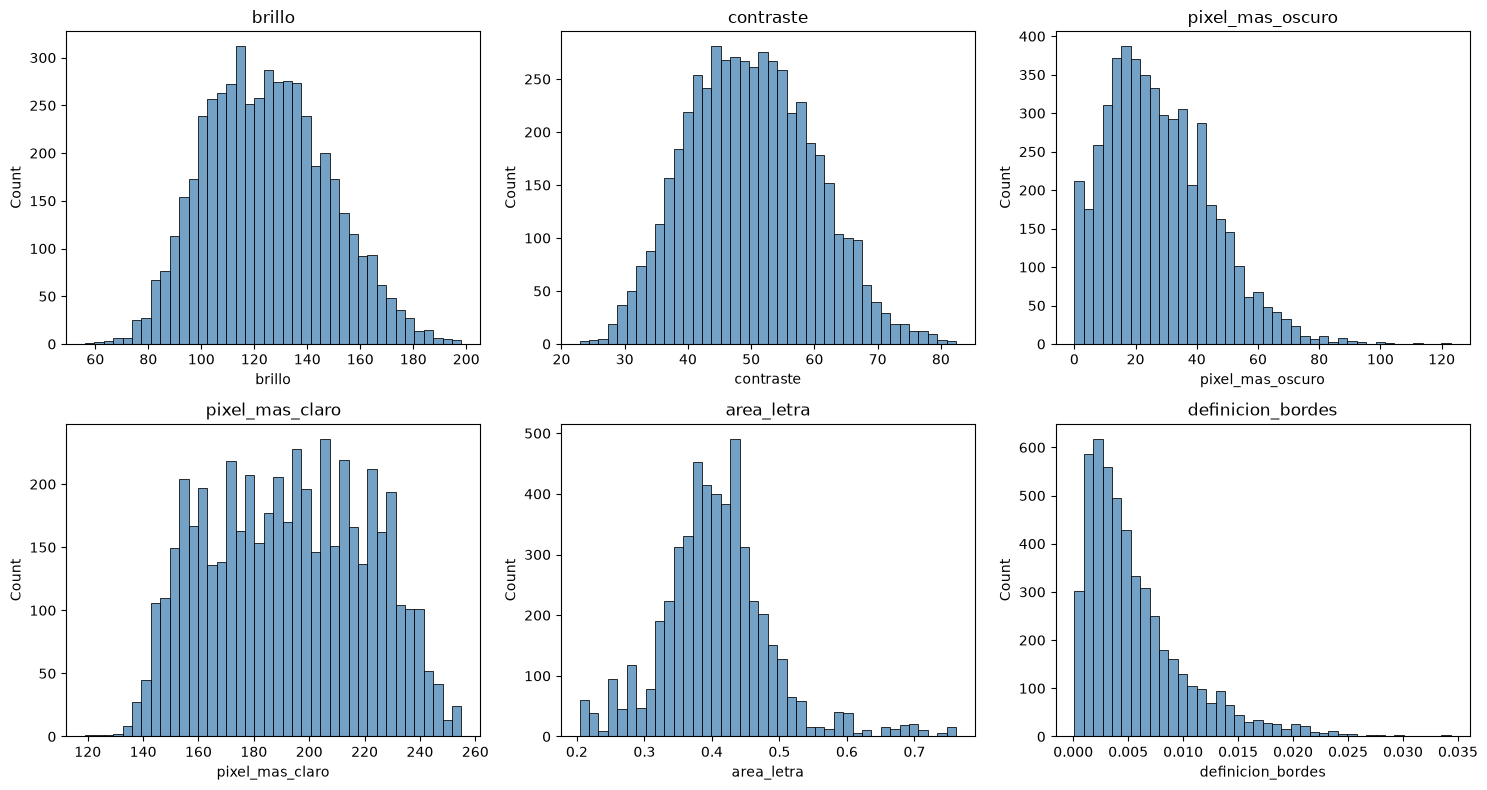

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), columnas):
    sns.histplot(df[col], bins=40, ax=ax, color="steelblue")
    ax.set_title(f"{col}")
plt.tight_layout()
plt.show()

### Diagramas de caja por vocal

Los diagramas de caja permiten comparar la distribución de cada característica entre las vocales e identificar valores atípicos.

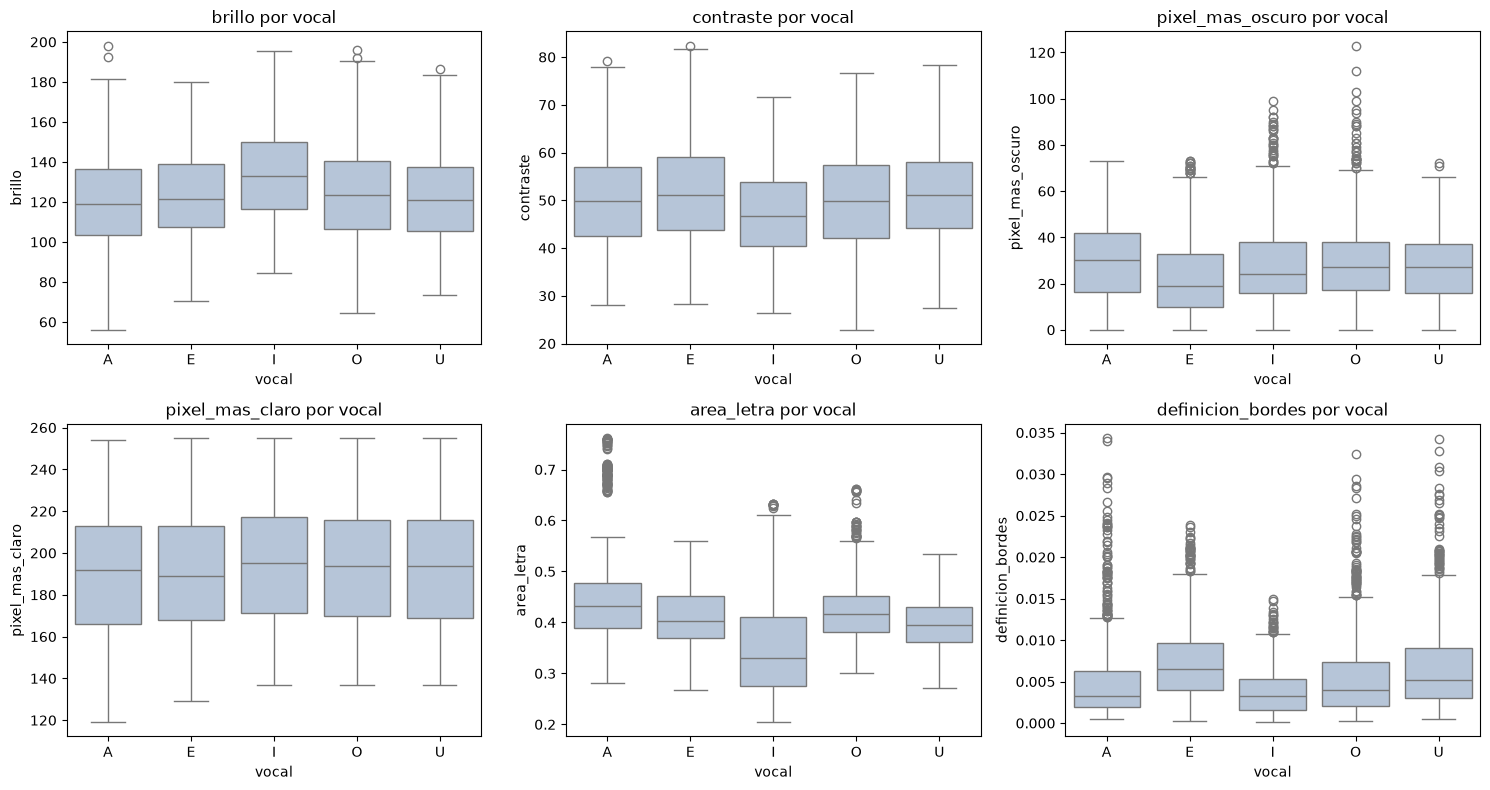

In [23]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), columnas):
    sns.boxplot(data=df, x="vocal", y=col, order=vocales, ax=ax, color="lightsteelblue")
    ax.set_title(f"{col} por vocal")
plt.tight_layout()
plt.show()